# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random
import os

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko)
from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 
os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

ML runs from high and low noise

In [2]:
runs_to_download = []
runs_to_download.extend(
    mlflow.search_runs(filter_string="attributes.status = 'FINISHED' and tags.run_type = 'model_training_and_prediction'",
                        experiment_ids=['7'], output_format='list'))
runs_to_download.extend(mlflow.search_runs(
    filter_string="attributes.status = 'FINISHED' and tags.run_type = 'model_training_and_prediction' and tags.mlflow.parentRunId = 'f02bf732b2ba4817b254bd5174f1549b'",
      experiment_ids=['6'], output_format='list'))
print(len(runs_to_download))
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-04-22 14:43:16,353 - INFO - Downloading artifacts for run cf8f67e98c774367ac795f3649870df0


18


2026-04-22 14:43:17,638 - INFO - Downloading artifacts for run e7c16d8357fd455698956ee1b9d608e3
2026-04-22 14:43:18,682 - INFO - Downloading artifacts for run 57560dff33bd47e9a5203ca2f718573b
2026-04-22 14:43:19,788 - INFO - Downloading artifacts for run a3e3ebf4de3b47e88853c58a321e8c6a
2026-04-22 14:43:20,846 - INFO - Downloading artifacts for run 9f2457ce38e140518cf35d3c05d4ba03
2026-04-22 14:43:21,893 - INFO - Downloading artifacts for run 2f3e46c732ee4af6934c5145d996a857
2026-04-22 14:43:22,957 - INFO - Downloading artifacts for run 374a8c6f09fe496f9b92dc2853947e02
2026-04-22 14:43:23,994 - INFO - Downloading artifacts for run 1bd5b2967c6f41739bc6e4211621e93b
2026-04-22 14:43:25,026 - INFO - Downloading artifacts for run 423588fe337243238d5037f32f73bbf0
2026-04-22 14:43:26,068 - INFO - Downloading artifacts for run 1ad11161345e42a09f550f7e061090c3
2026-04-22 14:43:27,089 - INFO - Downloading artifacts for run b815c94afd61404494ad9d222bf35214
2026-04-22 14:43:28,104 - INFO - Downloa

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.018256,0.018256,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a
1,Node_1,0.0,0.602953,0.602953,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a
2,Node_2,0.0,0.064996,0.064996,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a
3,Node_3,0.0,0.678937,0.678937,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a
4,Node_4,0.0,0.000000,0.000000,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a


In [3]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    run = mlflow.get_run(run_id)
    model_name_records.append({
        'run_id': run_id,
        'model_name': run.data.tags['mlflow.runName'],
        'modelled_genes': run.data.params.get('modelled_gene_labels', None)})
model_name_df = pd.DataFrame(model_name_records)
model_name_df

,run_id,model_name,modelled_genes
0,cf8f67e98c774367ac795f3649870df0,MLP,None
1,e7c16d8357fd455698956ee1b9d608e3,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod..."
2,57560dff33bd47e9a5203ca2f718573b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
3,a3e3ebf4de3b47e88853c58a321e8c6a,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
4,9f2457ce38e140518cf35d3c05d4ba03,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No..."
5,2f3e46c732ee4af6934c5145d996a857,HybridModel,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '..."
6,374a8c6f09fe496f9b92dc2853947e02,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
7,1bd5b2967c6f41739bc6e4211621e93b,HybridModel,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '..."
8,423588fe337243238d5037f32f73bbf0,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No..."
9,1ad11161345e42a09f550f7e061090c3,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."


In [4]:
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')

Add number of genes and noise level

In [5]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    run = mlflow.get_run(run_id)
    records.append({
        'parent_run_id': run_id,
        'nr_genes': run.data.params['nr_genes'],
        'noise_level': run.data.params['noise_level'],
    })
nr_genes_df = pd.DataFrame(records)
nr_genes_df.head()

,parent_run_id,nr_genes,noise_level
0,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
1,d97c3c9ca88a43b597b360151b25d316,50,HIGH
2,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM


Add noiseless expression values

In [6]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)
long_form_simulation = pd.concat(records, ignore_index=True)

2026-04-22 14:43:44,224 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 14:43:44,256 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 14:43:44,266 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 14:43:44,271 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 14:43:44,286 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 14:43:44,301 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 14:43:44,316 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-22 14:43:44,329 - WARNING - Connection p

In [7]:
nr_genes_df.head()

,parent_run_id,nr_genes,noise_level
0,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
1,d97c3c9ca88a43b597b360151b25d316,50,HIGH
2,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM


In [8]:
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes
0,Node_0,0.0,0.018256,0.018256,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None
1,Node_1,0.0,0.602953,0.602953,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None
2,Node_2,0.0,0.064996,0.064996,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None
3,Node_3,0.0,0.678937,0.678937,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None
4,Node_4,0.0,0.000000,0.000000,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None


In [9]:
long_form_simulation.head()

,gene,time,ground_truth,condition,run_id
0,Node_0,0.0,0.022225,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a
1,Node_1,0.0,0.557310,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a
2,Node_2,0.0,0.080057,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a
3,Node_3,0.0,0.702816,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a
4,Node_4,0.0,0.057769,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a


Merging

In [10]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])

outcome = pd.merge(outcome, nr_genes_df, on='parent_run_id')

In [11]:
outcome

,gene,time,predicted_expression,ground_truth_from_pred_df,condition,run_id_from_pred_df,parent_run_id,model_name,modelled_genes,ground_truth_from_simulation,run_id_from_simulation,nr_genes,noise_level
0,Node_0,0.0,0.018256,0.018256,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None,0.022225,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
1,Node_1,0.0,0.602953,0.602953,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None,0.557310,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
2,Node_2,0.0,0.064996,0.064996,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None,0.080057,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
3,Node_3,0.0,0.678937,0.678937,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None,0.702816,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
4,Node_4,0.0,0.000000,0.000000,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None,0.057769,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1889995,Node_45,1.0,1.003480,0.821199,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,0.925542,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM
1889996,Node_46,1.0,0.394155,0.294828,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,0.321352,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM
1889997,Node_47,1.0,0.190476,0.136453,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,0.138196,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM
1889998,Node_48,1.0,0.806056,0.756552,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,0.833160,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM


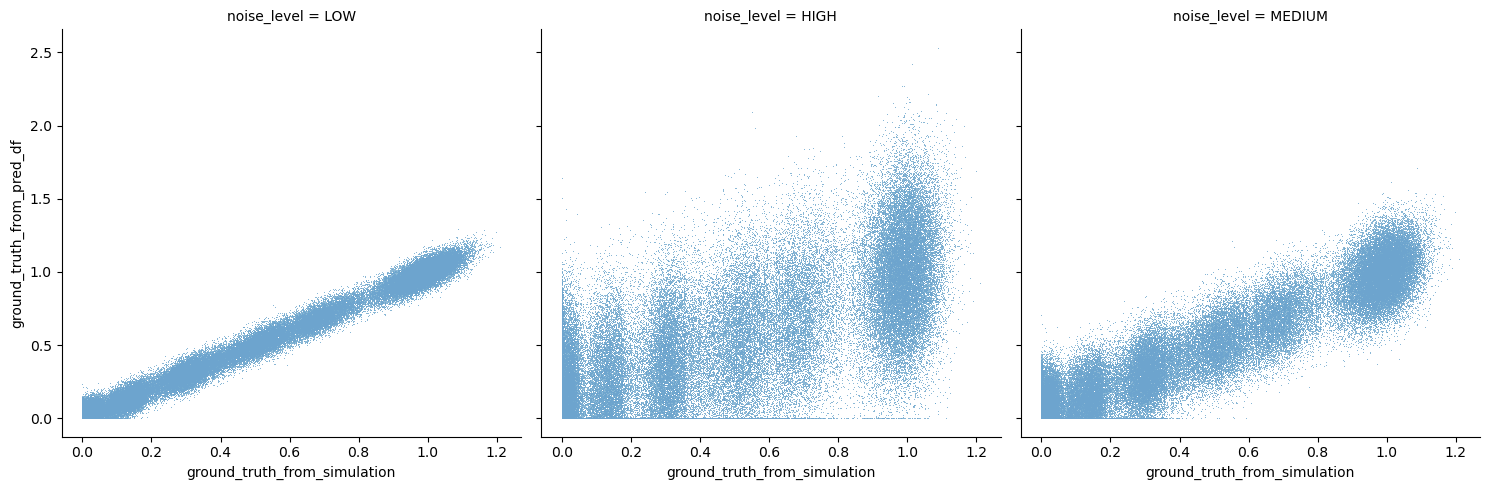

In [12]:
sns.relplot(data=outcome, x='ground_truth_from_simulation', y='ground_truth_from_pred_df', col='noise_level', s=2, alpha=.2, marker='.')

In [13]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation', 'noise_level']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})


outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,noise_level
0,Node_0,0.0,0.018256,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,MLP,None,0.022225,LOW
1,Node_1,0.0,0.602953,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,MLP,None,0.557310,LOW
2,Node_2,0.0,0.064996,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,MLP,None,0.080057,LOW
3,Node_3,0.0,0.678937,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,MLP,None,0.702816,LOW
4,Node_4,0.0,0.000000,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,MLP,None,0.057769,LOW
...,...,...,...,...,...,...,...,...,...
1889995,Node_45,1.0,1.003480,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.925542,MEDIUM
1889996,Node_46,1.0,0.394155,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.321352,MEDIUM
1889997,Node_47,1.0,0.190476,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.138196,MEDIUM
1889998,Node_48,1.0,0.806056,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.833160,MEDIUM


In [14]:
outcome['model_name_long'] = outcome['model_name'] + outcome['modelled_genes'].str[:20].fillna('')
outcome['model_name_long'].nunique()

6

In [15]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

In [16]:
from matplotlib.colors import LogNorm, Normalize
from sklearn.metrics import mean_squared_error
import scipy.cluster.hierarchy as sch
from natsort import natsorted
import re

robust_cmap = True
norm_function = Normalize
cmap = "viridis"

groupby_list = [
    'model_name',
    'modelled_genes',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    'noise_level'
]
mse_df = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)

mlp_mse = mse_df[mse_df['model_name'] == 'MLP'][['gene', 'condition', 'noise_level', 'MSE']].rename(columns={'MSE': 'mlp_mse'})
hybrid_mse = mse_df[mse_df['model_name'] == 'HybridModel'][['gene', 'condition', 'noise_level', 'MSE', 'modelled_genes']].rename(columns={'MSE': 'hybrid_mse'})

paired = hybrid_mse.merge(mlp_mse, on=['gene', 'condition', 'noise_level'])


def make_ko_lookup(df):
    unique_combos = df[['condition', 'modelled_genes']].drop_duplicates()
    
    lookup = {}
    for _, row in unique_combos.iterrows():
        cond = row['condition']
        genes = row['modelled_genes']
        kos = re.findall(r"Node_\d+", cond)
        
        if all(f"'{ko}'" in genes for ko in kos):
            ko_in_modelled_genes = 'fully'
        elif any(f"'{ko}'" in genes for ko in kos):
            ko_in_modelled_genes = 'partially'
        else:
            ko_in_modelled_genes = 'none'
        
        key = (cond, genes)
        lookup[key] = ko_in_modelled_genes
    
    return lookup

lookup = make_ko_lookup(paired)
paired['gene_ko_in_mechanistic_model'] = paired.apply(
    lambda row: lookup[(
        row['condition'],
        row['modelled_genes'] if row['modelled_genes'] is not None else None
    )],
    axis=1
)
paired['gene_in_mm'] = paired.apply(lambda row:
             bool(re.search(rf"'{row['gene']}'", row['modelled_genes'])), axis=1)

In [17]:
groupby_list = [
    'model_name_long',
    'modelled_genes',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    'noise_level'
]
mse_df_long_model_name = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)


In [47]:
mse_df_long_model_name

,model_name_long,modelled_genes,gene,condition,noise_level,MSE
0,"HybridModel['Node_11', 'Node_1'","['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",Node_0,"KO: Node_0, Node_13. Env: None",HIGH,0.030107
1,"HybridModel['Node_11', 'Node_1'","['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",Node_0,"KO: Node_0, Node_13. Env: None",LOW,0.053399
2,"HybridModel['Node_11', 'Node_1'","['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",Node_0,"KO: Node_0, Node_13. Env: None",MEDIUM,0.034132
3,"HybridModel['Node_11', 'Node_1'","['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",Node_0,"KO: Node_0, Node_19. Env: None",HIGH,0.050761
4,"HybridModel['Node_11', 'Node_1'","['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",Node_0,"KO: Node_0, Node_19. Env: None",LOW,0.064798
...,...,...,...,...,...,...
44995,MLP,NaN,Node_9,"KO: Node_8, Node_16. Env: None",LOW,0.001705
44996,MLP,NaN,Node_9,"KO: Node_8, Node_16. Env: None",MEDIUM,0.002025
44997,MLP,NaN,Node_9,"KO: Node_8, Node_31. Env: None",HIGH,0.040440
44998,MLP,NaN,Node_9,"KO: Node_8, Node_31. Env: None",LOW,0.000707


In [54]:
mse_df_long_model_name['gene_in_mm'] = mse_df_long_model_name.apply(
    lambda row: bool(re.search(rf"'{row['gene']}'", row['modelled_genes']))
    if row['modelled_genes'] is not None and isinstance(row['modelled_genes'], str)
    else False,
    axis=1
)

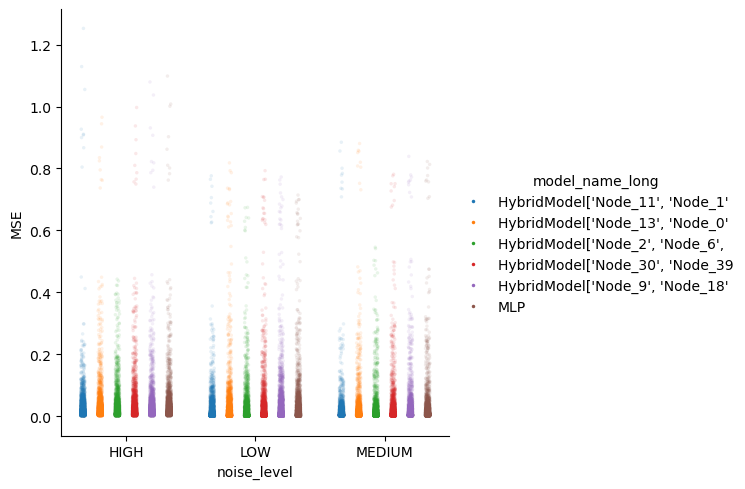

In [18]:

g= sns.catplot(data=mse_df_long_model_name, hue='model_name_long', x='noise_level', y='MSE', kind='strip', dodge=True, marker='.', alpha=.1 )
# g.set(yscale='log')
for lh in g.legend.legend_handles:
    lh.set_alpha(1)
    # lh.set_sizes([100])

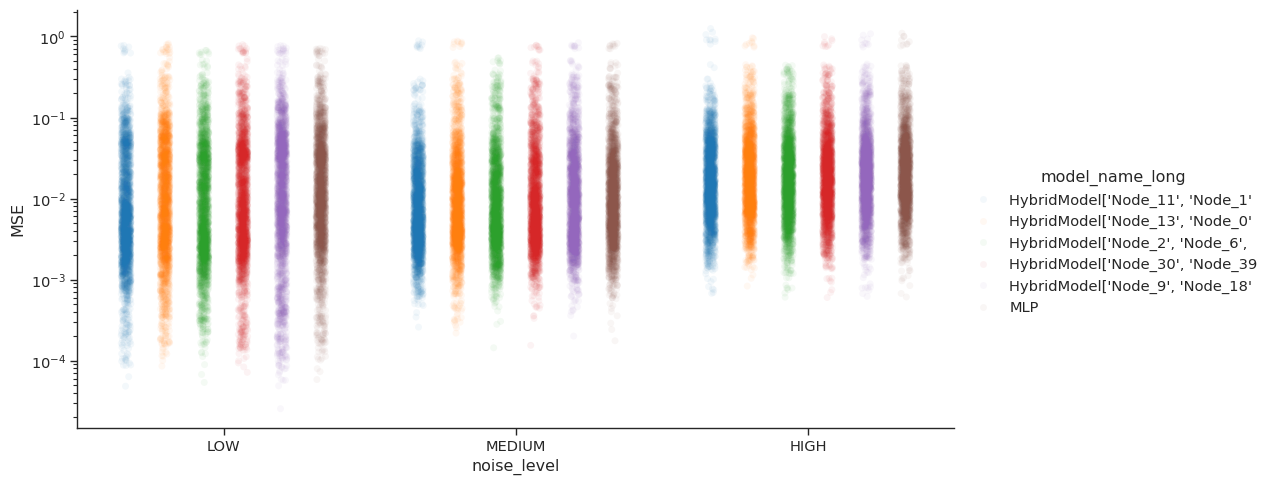

In [40]:
g= sns.catplot(data=mse_df_long_model_name, hue='model_name_long', x='noise_level', y='MSE', kind='strip', order=['LOW', 'MEDIUM', 'HIGH'],dodge=True, alpha=.05, aspect=2, log_scale=True )


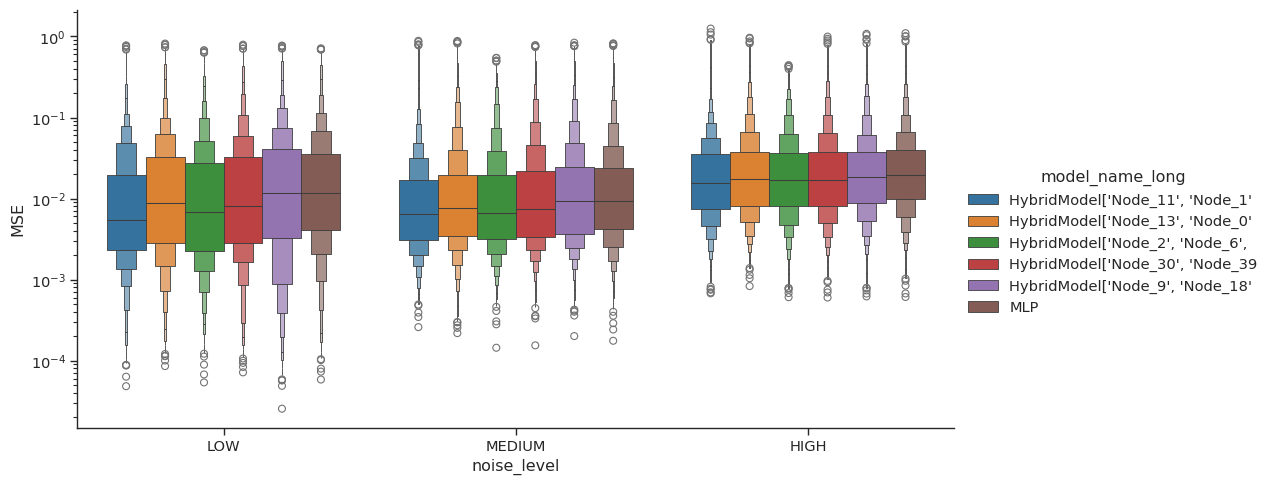

In [57]:
g= sns.catplot(data=mse_df_long_model_name, hue='model_name_long', x='noise_level', y='MSE', kind='boxen', order=['LOW', 'MEDIUM', 'HIGH'], aspect=2, log_scale=True,
                saturation = .7)


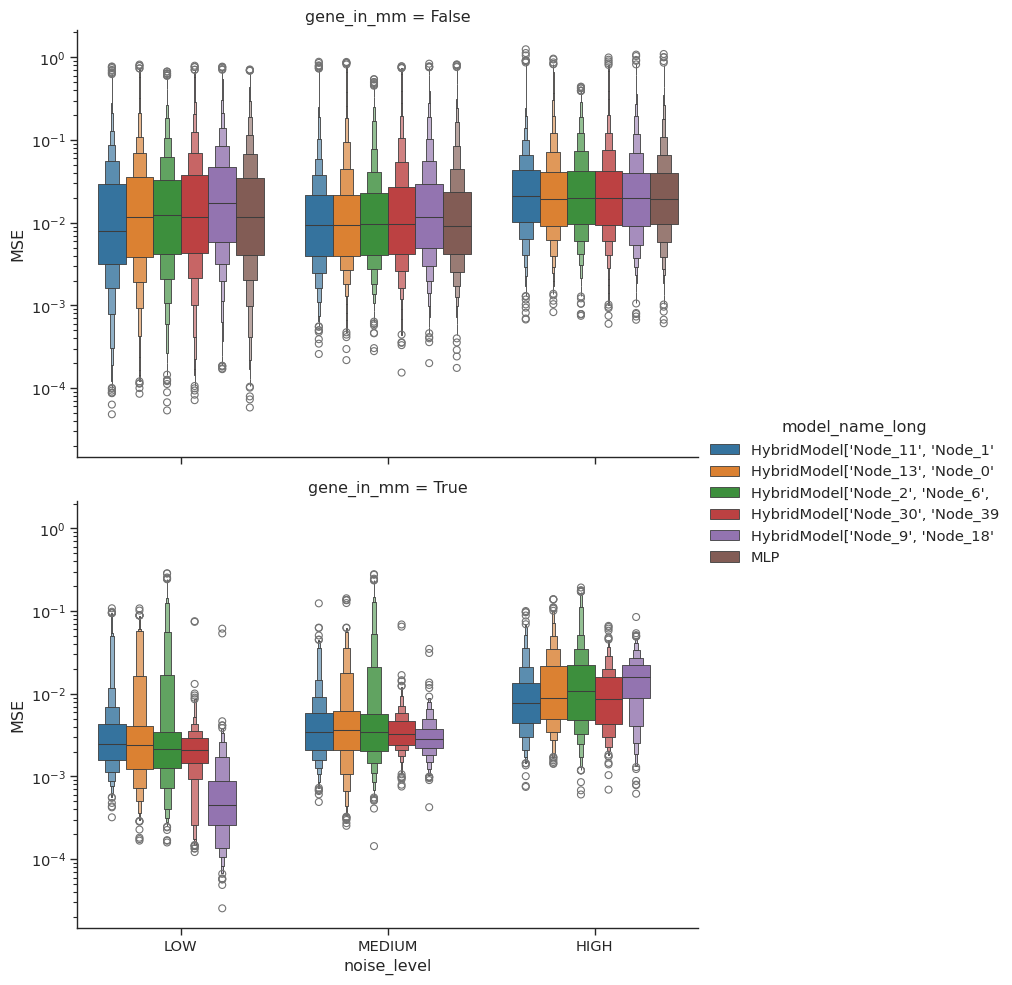

In [62]:
g= sns.catplot(data=mse_df_long_model_name, hue='model_name_long', x='noise_level', y='MSE', kind='boxen', order=['LOW', 'MEDIUM', 'HIGH'], aspect=1.5, log_scale=True,
                saturation = .7, row='gene_in_mm')


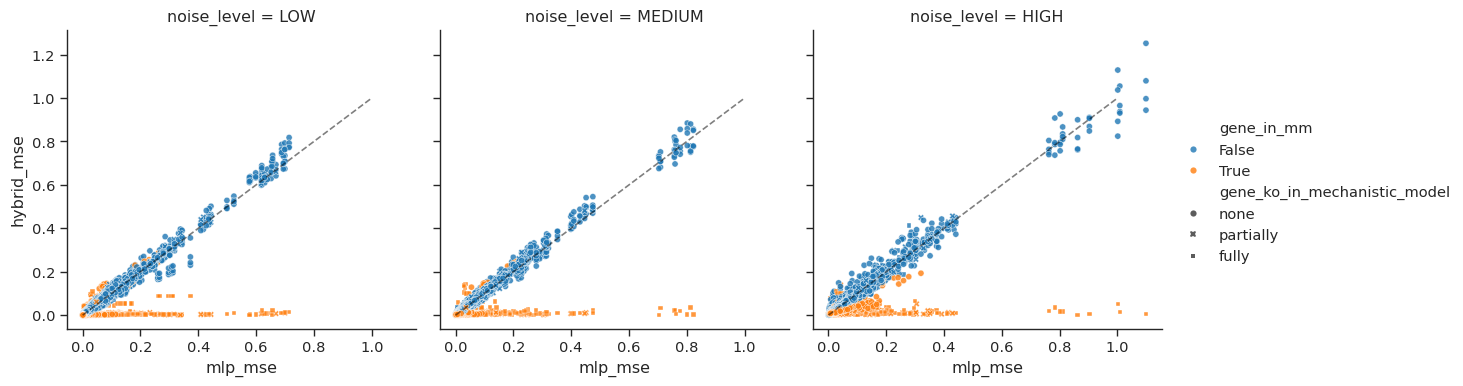

In [20]:
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', col='noise_level', hue='gene_in_mm', 
                style='gene_ko_in_mechanistic_model',  alpha=.8, s=20, col_order=['LOW', 'MEDIUM', 'HIGH'], height=4, aspect=1)

for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
#     for collection in ax.collections:
#         collection.set_rasterized(True)
# # plt.tight_layout()
# g.savefig("mm_size_comparison.pdf", dpi=600, bbox_inches='tight', )

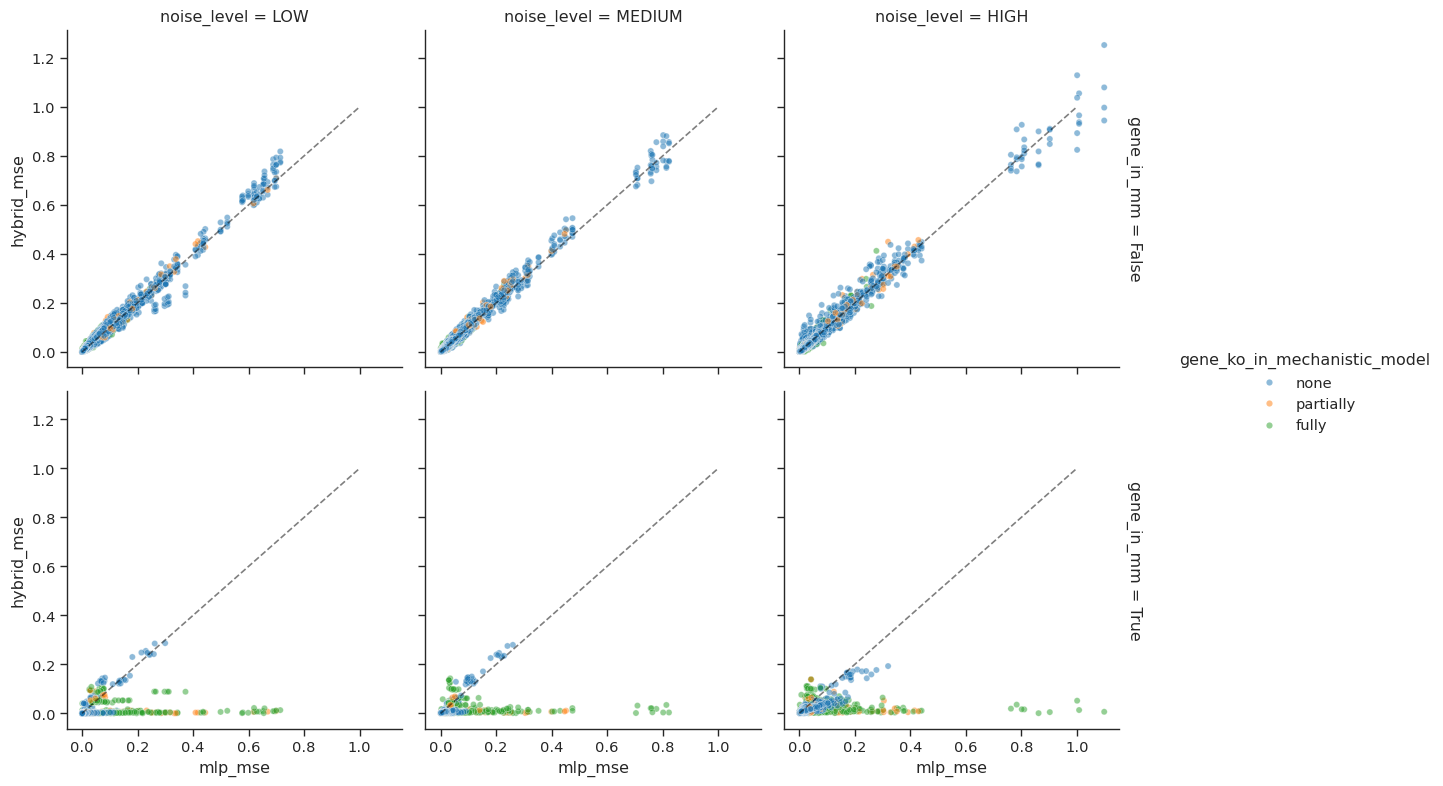

In [21]:
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', col='noise_level', row='gene_in_mm',
                row_order=[False, True], col_order=['LOW', 'MEDIUM', 'HIGH'], hue='gene_ko_in_mechanistic_model',  
                alpha=.5, s=20, height=4, aspect=1, facet_kws={'margin_titles': True})

for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
#     for collection in ax.collections:
#         collection.set_rasterized(True)
# # plt.tight_layout()
# g.savefig("mm_size_comparison.pdf", dpi=600, bbox_inches='tight', )

In [22]:
paired

,gene,condition,noise_level,hybrid_mse,modelled_genes,mlp_mse,gene_ko_in_mechanistic_model,gene_in_mm
0,Node_0,"KO: Node_0, Node_13. Env: None",HIGH,0.030107,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.027386,none,False
1,Node_0,"KO: Node_0, Node_13. Env: None",LOW,0.053399,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.057201,none,False
2,Node_0,"KO: Node_0, Node_13. Env: None",MEDIUM,0.034132,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.033210,none,False
3,Node_0,"KO: Node_0, Node_19. Env: None",HIGH,0.050761,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.042280,none,False
4,Node_0,"KO: Node_0, Node_19. Env: None",LOW,0.064798,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.070121,none,False
...,...,...,...,...,...,...,...,...
37495,Node_9,"KO: Node_8, Node_16. Env: None",LOW,0.000144,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.001705,none,True
37496,Node_9,"KO: Node_8, Node_16. Env: None",MEDIUM,0.002589,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.002025,none,True
37497,Node_9,"KO: Node_8, Node_31. Env: None",HIGH,0.018519,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.040440,none,True
37498,Node_9,"KO: Node_8, Node_31. Env: None",LOW,0.000272,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.000707,none,True


In [63]:
mse_df.head()

,model_name,modelled_genes,gene,condition,noise_level,MSE
0,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",Node_0,"KO: Node_0, Node_13. Env: None",HIGH,0.030107
1,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",Node_0,"KO: Node_0, Node_13. Env: None",LOW,0.053399
2,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",Node_0,"KO: Node_0, Node_13. Env: None",MEDIUM,0.034132
3,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",Node_0,"KO: Node_0, Node_19. Env: None",HIGH,0.050761
4,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",Node_0,"KO: Node_0, Node_19. Env: None",LOW,0.064798


In [ ]:
import matplotlib.colors as mcolors

hybrid_names = [n for n in mse_df_long_model_name['model_name_long'].unique() if 'HybridModel' in n]
mlp_names = [n for n in mse_df_long_model_name['model_name_long'].unique() if 'HybridModel' not in n]

blue_cmap = plt.cm.Blues(np.linspace(0.4, 0.9, len(hybrid_names)))
red_cmap = plt.cm.Reds(np.linspace(0.4, 0.9, len(mlp_names)))

palette = {name: mcolors.to_hex(colour) for name, colour in zip(hybrid_names, blue_cmap)}
palette.update({name: mcolors.to_hex(colour) for name, colour in zip(mlp_names, red_cmap)})

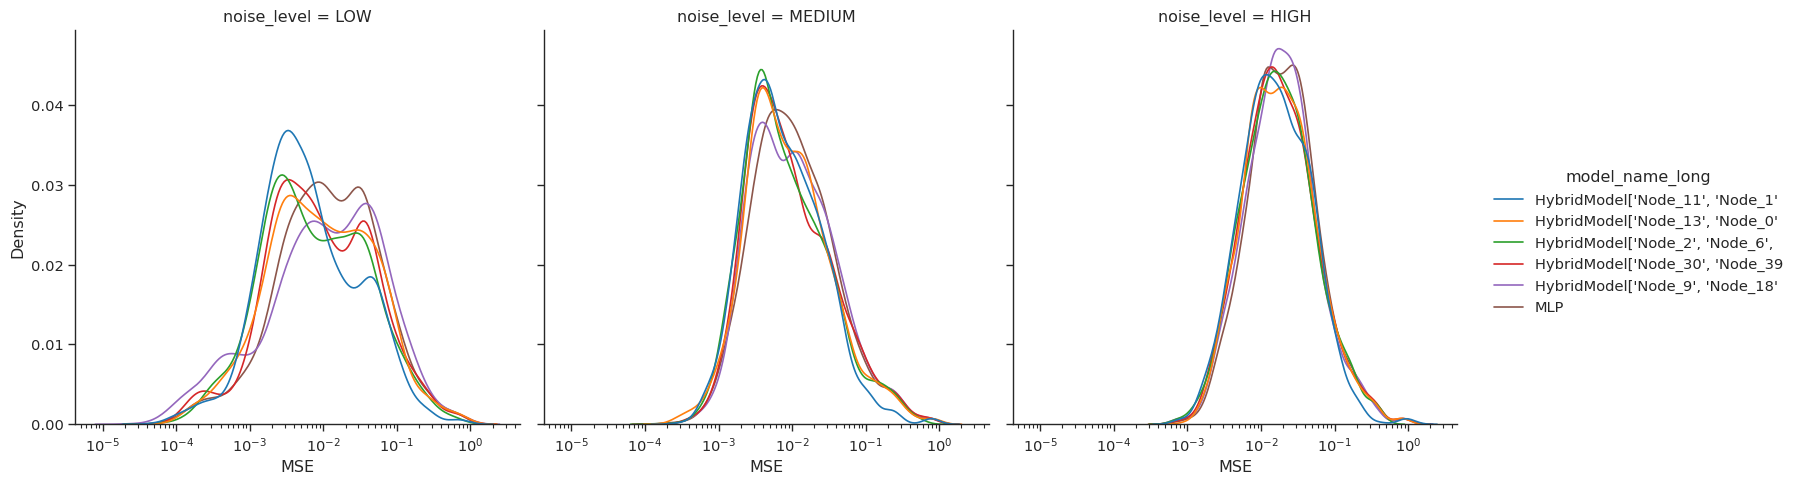

In [72]:
sns.displot(data=mse_df_long_model_name, col='noise_level', col_order=['LOW', 'MEDIUM', 'HIGH'], x='MSE', hue='model_name_long', kind='kde', log_scale=True)

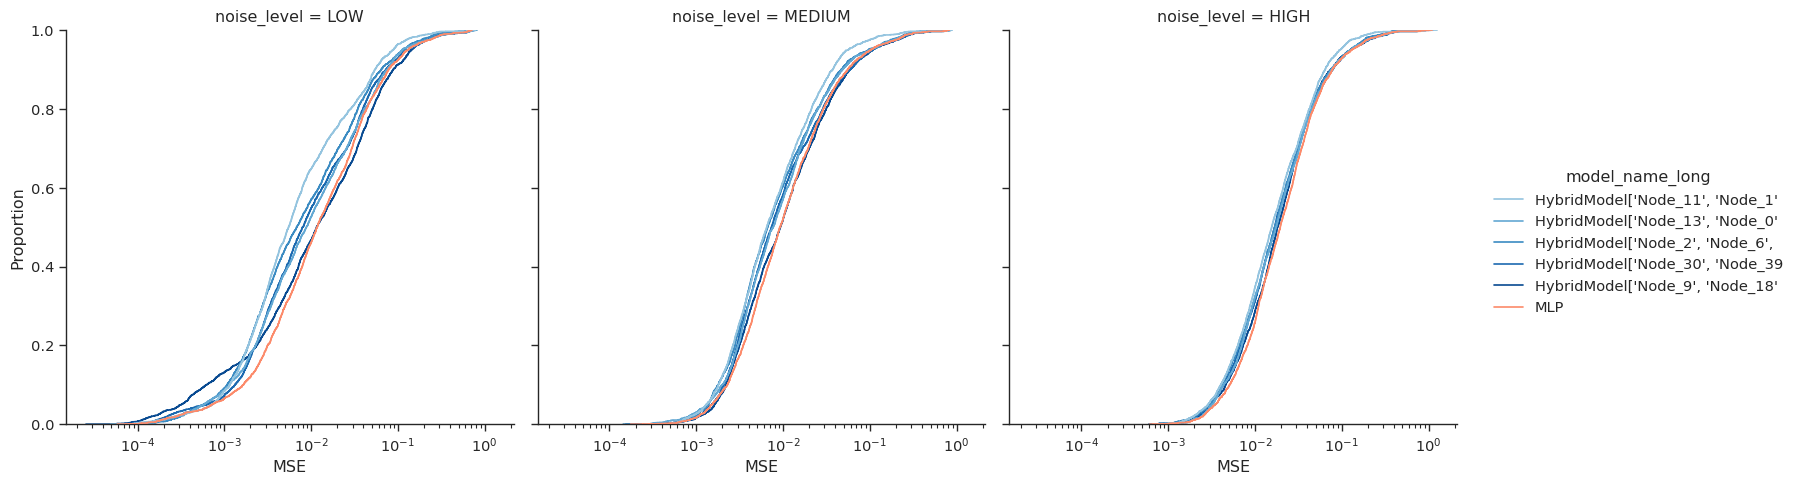

In [84]:
g = sns.displot(data=mse_df_long_model_name, col='noise_level', col_order=['LOW', 'MEDIUM', 'HIGH'], x='MSE', hue='model_name_long', kind='ecdf', log_scale=True, palette=palette)

for ax in g.axes.flat:
    lines = ax.get_lines()
    for line in lines:
        if mcolors.to_hex(line.get_color()) in [palette[name] for name in mlp_names]:
            line.set_zorder(10)

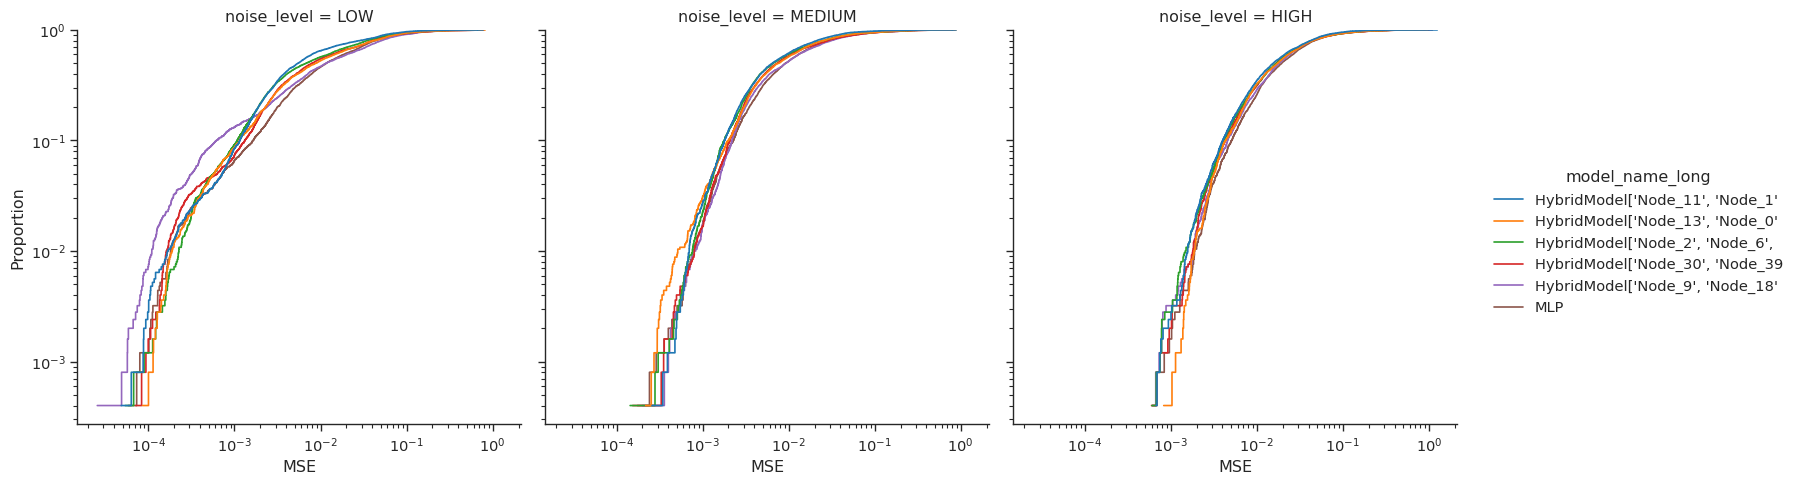

In [73]:
sns.displot(data=mse_df_long_model_name, col='noise_level', col_order=['LOW', 'MEDIUM', 'HIGH'], x='MSE', hue='model_name_long', kind='ecdf', log_scale=(True, True))

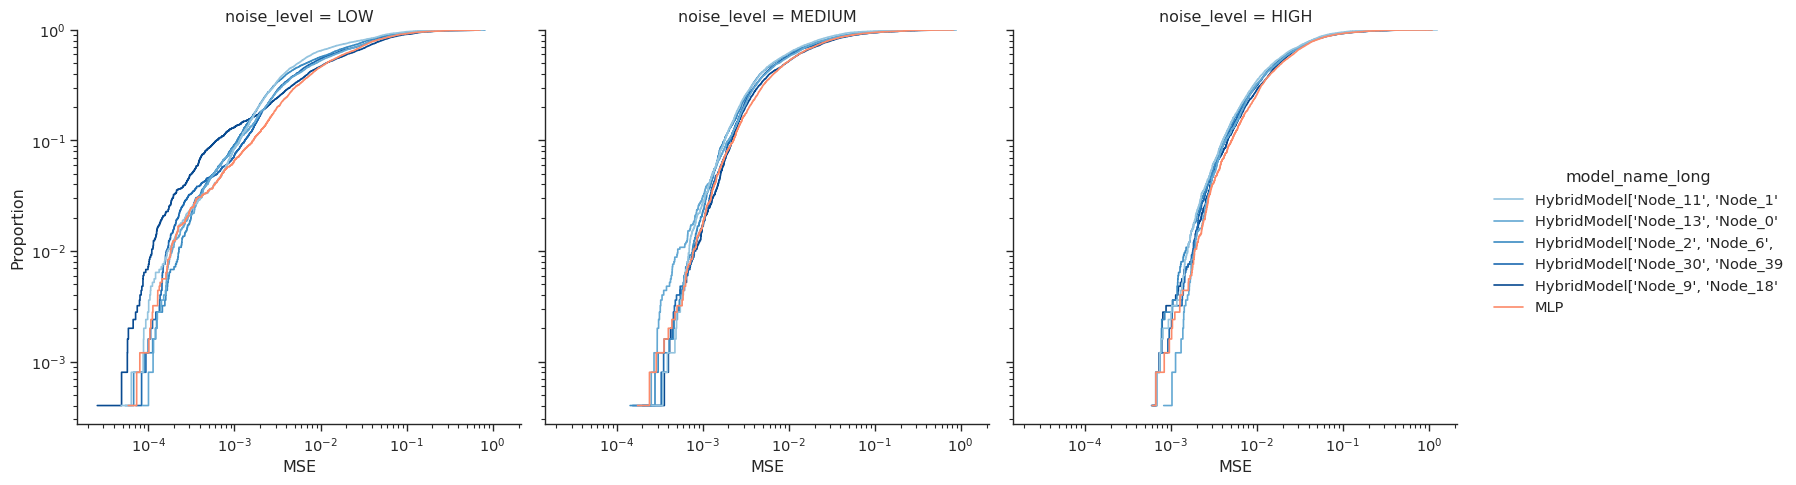

In [81]:
g = sns.displot(data=mse_df_long_model_name, col='noise_level', col_order=['LOW', 'MEDIUM', 'HIGH'], x='MSE', hue='model_name_long', kind='ecdf', log_scale=(True, True), palette=palette)

for ax in g.axes.flat:
    lines = ax.get_lines()
    for line in lines:
        if mcolors.to_hex(line.get_color()) in [palette[name] for name in mlp_names]:
            line.set_zorder(10)

In [23]:
selection = paired[paired['gene_in_mm'] == True]

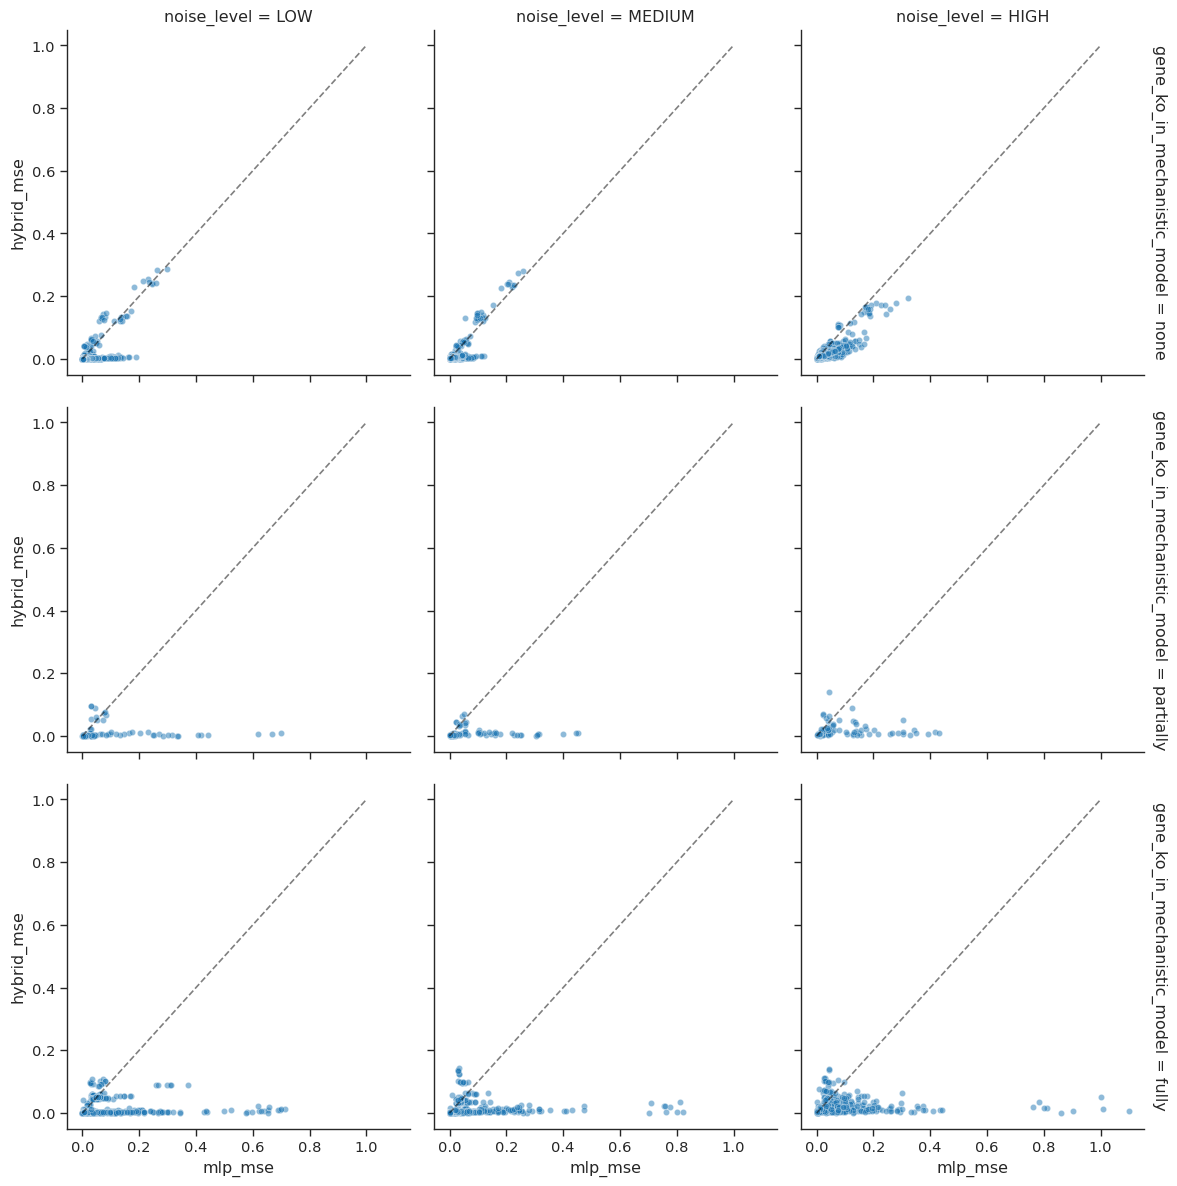

In [26]:
g = sns.relplot(data=selection, x='mlp_mse', y='hybrid_mse', col='noise_level', row='gene_ko_in_mechanistic_model',
                  alpha=.5, s=20, height=4, aspect=1, facet_kws={'margin_titles': True}, col_order=['LOW', 'MEDIUM', 'HIGH'])

for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)